# Импорты и пути

In [3]:
from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
from ultralytics import YOLO

# ============================================================
# PATHS
# ============================================================

# Датасет находится отдельно
dataset_path = Path(r"C:\Users\Ева\Desktop\Хакатон\data_preproc\constraction_labelme")

images_path = dataset_path / "images"
labels_path = dataset_path / "labels"

# Текущая папка = YoloE
world_path = Path(".")

# Модель лежит непосредственно в YoloE
model_path = world_path / "yoloe-26m-seg.pt"

# Результаты тоже внутри YoloE, но отдельно от датасета
results_root = world_path / "yoloe_experiments"
results_root.mkdir(parents=True, exist_ok=True)

print("Dataset :", dataset_path.resolve())
print("Model   :", model_path.resolve())
print("Results :", results_root.resolve())

Dataset : C:\Users\Ева\Desktop\Хакатон\data_preproc\constraction_labelme
Model   : C:\Users\Ева\Desktop\Хакатон\YoloE\yoloe-26m-seg.pt
Results : C:\Users\Ева\Desktop\Хакатон\YoloE\yoloe_experiments


# Ground Truth

In [4]:
# ============================================================
# CLASSES
# ============================================================

eval_classes = [
    "truck",
    "excavator",
    "concrete mixer"
]

label_to_class = {
    "грузовик": "truck",
    "экскаватор": "excavator",
    "бетономешалка": "concrete mixer"
}


# ============================================================
# LOAD LABELME GT
# ============================================================

ground_truth = {}

for json_file in labels_path.glob("*.json"):

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    objects = []

    for shape in data.get("shapes", []):

        label = shape["label"]

        if label not in label_to_class:
            continue

        points = np.array(shape["points"], dtype=float)

        bbox = [
            float(points[:, 0].min()),
            float(points[:, 1].min()),
            float(points[:, 0].max()),
            float(points[:, 1].max())
        ]

        objects.append({
            "class": label_to_class[label],
            "original_class": label,
            "bbox": bbox
        })

    ground_truth[json_file.stem] = objects


# ============================================================
# IMAGES
# ============================================================

image_files = sorted([
    p for p in images_path.iterdir()
    if p.suffix.lower() in [
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    ]
])


print(f"Images: {len(image_files)}")
print(f"GT files: {len(ground_truth)}")

for cls in eval_classes:

    count = sum(
        1
        for objects in ground_truth.values()
        for obj in objects
        if obj["class"] == cls
    )

    print(f"{cls}: {count}")

Images: 3651
GT files: 3651
truck: 4057
excavator: 2359
concrete mixer: 1118


# YOLOE-26m + prompts

In [5]:
# ============================================================
# MODEL
# ============================================================

model = YOLO(str(model_path))

print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# PROMPT EXPERIMENTS
# ============================================================

experiments = {

    "01_baseline": [
        "truck",
        "excavator",
        "concrete mixer"
    ],

    "02_vehicle": [
        "truck vehicle",
        "excavator vehicle",
        "concrete mixer truck"
    ],

    "03_complete": [
        "a complete truck vehicle",
        "a complete excavator vehicle",
        "a complete concrete mixer truck"
    ],

    "04_construction": [
        "construction truck",
        "construction excavator",
        "concrete mixer truck"
    ],

    "05_heavy_equipment": [
        "heavy truck",
        "excavator construction machine",
        "concrete mixer truck"
    ],

    "06_specific": [
        "a road truck",
        "a tracked excavator",
        "a concrete mixer truck"
    ]
}

print("Experiments:", len(experiments))

CUDA: True
GPU: NVIDIA GeForce RTX 3070 Laptop GPU
Experiments: 6


# Метрики + функция эксперимента

In [6]:
# ============================================================
# IoU
# ============================================================

def iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - inter

    return inter / union if union > 0 else 0


# ============================================================
# TP / FP / FN
# ============================================================

def calculate_tpfpfn(predictions, iou_threshold=0.5):

    tp = {c: 0 for c in eval_classes}
    fp = {c: 0 for c in eval_classes}
    fn = {c: 0 for c in eval_classes}

    for image_stem, gt_objects in ground_truth.items():

        preds = predictions.get(image_stem, [])
        matched = set()

        preds = sorted(
            preds,
            key=lambda x: x["confidence"],
            reverse=True
        )

        for pred in preds:

            best_iou = 0
            best_idx = None

            for idx, gt in enumerate(gt_objects):

                if idx in matched:
                    continue

                if gt["class"] != pred["class"]:
                    continue

                current_iou = iou(
                    pred["bbox"],
                    gt["bbox"]
                )

                if current_iou > best_iou:
                    best_iou = current_iou
                    best_idx = idx

            if best_iou >= iou_threshold:

                tp[pred["class"]] += 1
                matched.add(best_idx)

            else:

                fp[pred["class"]] += 1

        for idx, gt in enumerate(gt_objects):

            if idx not in matched:
                fn[gt["class"]] += 1

    return tp, fp, fn


# ============================================================
# AP
# ============================================================

def calculate_ap(predictions, target_class, iou_threshold):

    gt_by_image = {
        image: [
            obj for obj in objects
            if obj["class"] == target_class
        ]
        for image, objects in ground_truth.items()
    }

    total_gt = sum(len(v) for v in gt_by_image.values())

    if total_gt == 0:
        return 0.0

    all_preds = []

    for image, preds in predictions.items():

        for pred in preds:

            if pred["class"] == target_class:

                all_preds.append({
                    "image": image,
                    "confidence": pred["confidence"],
                    "bbox": pred["bbox"]
                })

    all_preds.sort(
        key=lambda x: x["confidence"],
        reverse=True
    )

    matched = {
        image: set()
        for image in gt_by_image
    }

    tp = []
    fp = []

    for pred in all_preds:

        gts = gt_by_image.get(pred["image"], [])

        best_iou = 0
        best_idx = None

        for idx, gt in enumerate(gts):

            if idx in matched[pred["image"]]:
                continue

            current_iou = iou(
                pred["bbox"],
                gt["bbox"]
            )

            if current_iou > best_iou:
                best_iou = current_iou
                best_idx = idx

        if best_iou >= iou_threshold:

            tp.append(1)
            fp.append(0)
            matched[pred["image"]].add(best_idx)

        else:

            tp.append(0)
            fp.append(1)

    if not tp:
        return 0.0

    tp = np.cumsum(tp)
    fp = np.cumsum(fp)

    recalls = tp / total_gt
    precisions = tp / np.maximum(tp + fp, 1e-9)

    recall_points = np.linspace(0, 1, 101)

    ap = 0

    for r in recall_points:

        valid = precisions[recalls >= r]

        ap += valid.max() if len(valid) else 0

    return ap / 101


# ============================================================
# RUN EXPERIMENT
# ============================================================

def run_experiment(name, prompts, image_subset=None, conf=0.1):

    print(f"\n{'=' * 60}")
    print(name)
    print("Prompts:", prompts)
    print(f"{'=' * 60}")

    experiment_dir = results_root / name
    output_dir = experiment_dir / "images"

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # YOLOE open-vocabulary prompts
    model.set_classes(prompts)

    files = image_subset if image_subset is not None else image_files

    predictions = {}

    for image_file in tqdm(files, desc=name):

        image_stem = image_file.stem

        results = model.predict(
            source=str(image_file),
            conf=conf,
            verbose=False,
            device=0 if torch.cuda.is_available() else "cpu"
        )

        result = results[0]

        image_predictions = []

        # ====================================================
        # ИСПОЛЬЗУЕМ ТОЛЬКО BOUNDING BOXES
        # ====================================================

        if result.boxes is not None:

            for box in result.boxes:

                cls_id = int(box.cls.item())

                if cls_id >= len(eval_classes):
                    continue

                image_predictions.append({
                    "class": eval_classes[cls_id],
                    "confidence": float(box.conf.item()),
                    "bbox": [
                        float(x)
                        for x in box.xyxy[0].cpu().numpy()
                    ]
                })

        predictions[image_stem] = image_predictions

        # Сохраняем только BOXES
        annotated = result.plot(
            boxes=True,
            masks=False
        )

        cv2.imwrite(
            str(output_dir / image_file.name),
            annotated
        )


    # ========================================================
    # METRICS
    # ========================================================

    tp, fp, fn = calculate_tpfpfn(
        predictions,
        iou_threshold=0.5
    )

    metrics = {
        "experiment": name,
        "prompts": prompts,
        "images": len(files),

        "ground_truth_objects": sum(
            len(ground_truth.get(img.stem, []))
            for img in files
        ),

        "classes": {}
    }


    for cls in eval_classes:

        precision = (
            tp[cls] / (tp[cls] + fp[cls])
            if tp[cls] + fp[cls] else 0
        )

        recall = (
            tp[cls] / (tp[cls] + fn[cls])
            if tp[cls] + fn[cls] else 0
        )

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        ap50 = calculate_ap(
            predictions,
            cls,
            0.50
        )

        ap5095 = np.mean([
            calculate_ap(
                predictions,
                cls,
                threshold
            )
            for threshold in np.arange(0.50, 0.96, 0.05)
        ])

        metrics["classes"][cls] = {
            "TP": tp[cls],
            "FP": fp[cls],
            "FN": fn[cls],
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "mAP50": float(ap50),
            "mAP50-95": float(ap5095)
        }


    # Средние значения
    metrics["mean"] = {
        metric: float(np.mean([
            metrics["classes"][cls][metric]
            for cls in eval_classes
        ]))
        for metric in [
            "precision",
            "recall",
            "f1",
            "mAP50",
            "mAP50-95"
        ]
    }


    # ========================================================
    # SAVE
    # ========================================================

    with open(
        experiment_dir / "predictions.json",
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            predictions,
            f,
            ensure_ascii=False,
            indent=2
        )

    with open(
        experiment_dir / "metrics.json",
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            metrics,
            f,
            ensure_ascii=False,
            indent=2
        )


    print("\nMean metrics:")
    print(json.dumps(
        metrics["mean"],
        indent=2
    ))

    return metrics

# Тест

In [7]:
TEST_SIZE = 50

test_images = image_files[:TEST_SIZE]

test_results = {}

for name, prompts in experiments.items():

    test_results[name] = run_experiment(
        name=name,
        prompts=prompts,
        image_subset=test_images,
        conf=0.1
    )

print("\nТест завершён.")


01_baseline
Prompts: ['truck', 'excavator', 'concrete mixer']
WARNING Download failure, retrying 1/3 https://github.com/ultralytics/assets/releases/download/v8.4.0/mobileclip2_b.ts... ('Connection broken: IncompleteRead(12844246 bytes read, 240950230 more expected)', IncompleteRead(12844246 bytes read, 240950230 more expected))


c:\Users\Ева\Desktop\Хакатон\venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
01_baseline: 100%|██████████| 50/50 [00:04<00:00, 12.30it/s]



Mean metrics:
{
  "precision": 0.3547418967587035,
  "recall": 0.006372140337759347,
  "f1": 0.01250464945809822,
  "mAP50": 0.006600660066006601,
  "mAP50-95": 0.0066006600660066
}

02_vehicle
Prompts: ['truck vehicle', 'excavator vehicle', 'concrete mixer truck']


02_vehicle: 100%|██████████| 50/50 [00:01<00:00, 27.16it/s]



Mean metrics:
{
  "precision": 0.32922522522522524,
  "recall": 0.006736908479070797,
  "f1": 0.013173158835585215,
  "mAP50": 0.009075907590759076,
  "mAP50-95": 0.007095709570957095
}

03_complete
Prompts: ['a complete truck vehicle', 'a complete excavator vehicle', 'a complete concrete mixer truck']


...


Mean metrics:
{
  "precision": 0.308974358974359,
  "recall": 0.004065250900957804,
  "f1": 0.007974788424979116,
  "mAP50": 0.004473780711404474,
  "mAP50-95": 0.0042624504226644174
}

05_heavy_equipment
Prompts: ['heavy truck', 'excavator construction machine', 'concrete mixer truck']


05_heavy_equipment: 100%|██████████| 50/50 [00:01<00:00, 26.80it/s]



Mean metrics:
{
  "precision": 0.2630208333333333,
  "recall": 0.004029132829484495,
  "f1": 0.007860634447369627,
  "mAP50": 0.006600660066006601,
  "mAP50-95": 0.0066006600660066
}

06_specific
Prompts: ['a road truck', 'a tracked excavator', 'a concrete mixer truck']


06_specific: 100%|██████████| 50/50 [00:01<00:00, 25.21it/s]



Mean metrics:
{
  "precision": 0.6392857142857143,
  "recall": 0.008739949264880833,
  "f1": 0.017235510242896126,
  "mAP50": 0.012352663837812354,
  "mAP50-95": 0.010900518623290901
}

Тест завершён.


# Полный запуск

In [8]:
# ============================================================
# FULL RUN
# ============================================================

all_results = {}

for name, prompts in experiments.items():

    all_results[name] = run_experiment(
        name=name,
        prompts=prompts,
        image_subset=image_files,
        conf=0.1
    )


# ============================================================
# SUMMARY
# ============================================================

rows = []

for name, result in all_results.items():

    row = {
        "experiment": name,
        "precision": result["mean"]["precision"],
        "recall": result["mean"]["recall"],
        "F1": result["mean"]["f1"],
        "mAP50": result["mean"]["mAP50"],
        "mAP50-95": result["mean"]["mAP50-95"]
    }

    for cls in eval_classes:

        row[f"{cls}_P"] = result["classes"][cls]["precision"]
        row[f"{cls}_R"] = result["classes"][cls]["recall"]
        row[f"{cls}_mAP50"] = result["classes"][cls]["mAP50"]
        row[f"{cls}_mAP50-95"] = result["classes"][cls]["mAP50-95"]

    rows.append(row)


summary = pd.DataFrame(rows)

summary = summary.sort_values(
    "mAP50",
    ascending=False
)


# CSV
summary.to_csv(
    results_root / "summary.csv",
    index=False,
    encoding="utf-8-sig"
)


# JSON
with open(
    results_root / "summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        all_results,
        f,
        ensure_ascii=False,
        indent=2
    )


display(summary)


01_baseline
Prompts: ['truck', 'excavator', 'concrete mixer']


01_baseline: 100%|██████████| 3651/3651 [02:38<00:00, 23.04it/s]



Mean metrics:
{
  "precision": 0.5361508306735624,
  "recall": 0.41932205859522265,
  "f1": 0.3805625953644128,
  "mAP50": 0.31152981425623855,
  "mAP50-95": 0.217995210161428
}

02_vehicle
Prompts: ['truck vehicle', 'excavator vehicle', 'concrete mixer truck']


02_vehicle: 100%|██████████| 3651/3651 [02:48<00:00, 21.68it/s]



Mean metrics:
{
  "precision": 0.4596220448802775,
  "recall": 0.4444207975459565,
  "f1": 0.3528637348246102,
  "mAP50": 0.3183705877713832,
  "mAP50-95": 0.22251221729634016
}

03_complete
Prompts: ['a complete truck vehicle', 'a complete excavator vehicle', 'a complete concrete mixer truck']


...

05_heavy_equipment: 100%|██████████| 3651/3651 [02:58<00:00, 20.50it/s]



Mean metrics:
{
  "precision": 0.42580459001077214,
  "recall": 0.3019555768523803,
  "f1": 0.2583781992285273,
  "mAP50": 0.16065635676851245,
  "mAP50-95": 0.10327266032032774
}

06_specific
Prompts: ['a road truck', 'a tracked excavator', 'a concrete mixer truck']


06_specific: 100%|██████████| 3651/3651 [02:57<00:00, 20.61it/s]



Mean metrics:
{
  "precision": 0.5762523470444966,
  "recall": 0.4880768350803903,
  "f1": 0.5043247517255082,
  "mAP50": 0.4041720765724474,
  "mAP50-95": 0.29881334395614684
}


,experiment,precision,recall,F1,mAP50,mAP50-95,truck_P,truck_R,truck_mAP50,truck_mAP50-95,excavator_P,excavator_R,excavator_mAP50,excavator_mAP50-95,concrete mixer_P,concrete mixer_R,concrete mixer_mAP50,concrete mixer_mAP50-95
5,06_specific,0.576252,0.488077,0.504325,0.404172,0.298813,0.501785,0.381070,0.214557,0.148912,0.574716,0.772785,0.705830,0.510283,0.652256,0.310376,0.292129,0.237245
2,03_complete,0.556947,0.451321,0.389747,0.347414,0.246077,0.439060,0.451072,0.235738,0.156730,0.473886,0.838491,0.739089,0.532651,0.757895,0.064401,0.067415,0.048852
1,02_vehicle,0.459622,0.444421,0.352864,0.318371,0.222512,0.297084,0.585161,0.263184,0.170477,0.581782,0.741840,0.682027,0.488727,0.500000,0.006261,0.009901,0.008333
0,01_baseline,0.536151,0.419322,0.380563,0.311530,0.217995,0.370490,0.539068,0.297845,0.201601,0.666534,0.711742,0.626844,0.445100,0.571429,0.007156,0.009901,0.007284
3,04_construction,0.597592,0.335501,0.324338,0.206486,0.138376,0.322024,0.552132,0.195568,0.109736,0.658252,0.431115,0.395784,0.286437,0.812500,0.023256,0.028106,0.018953
4,05_heavy_equipment,0.425805,0.301956,0.258378,0.160656,0.103273,0.270109,0.600937,0.203463,0.119870,0.578734,0.302247,0.268605,0.185988,0.428571,0.002683,0.009901,0.003960


# Графики

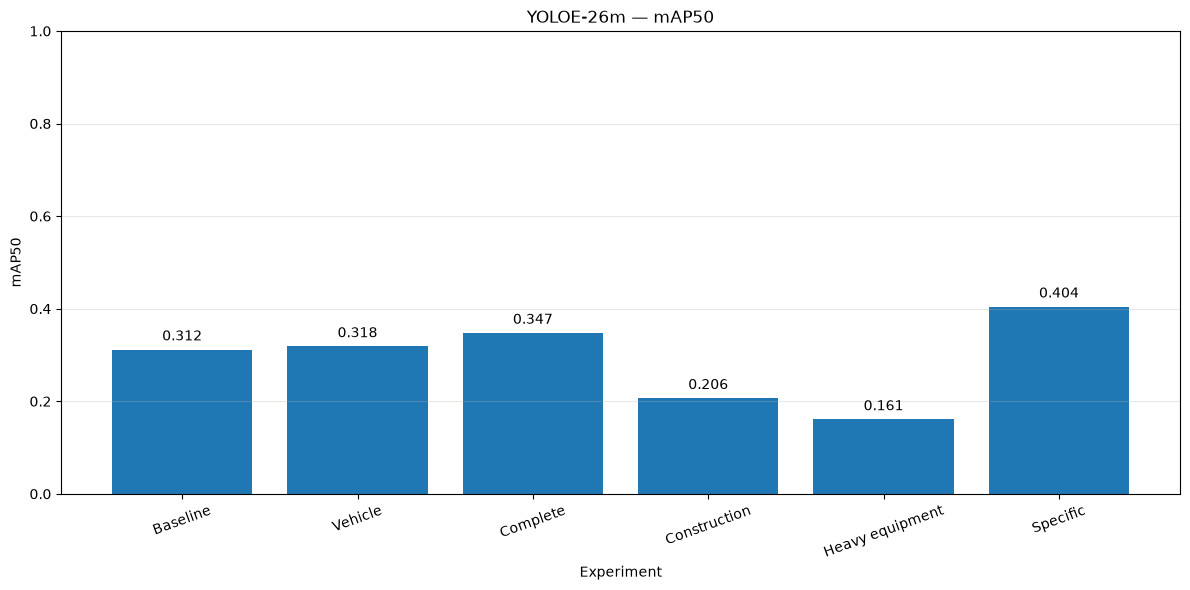

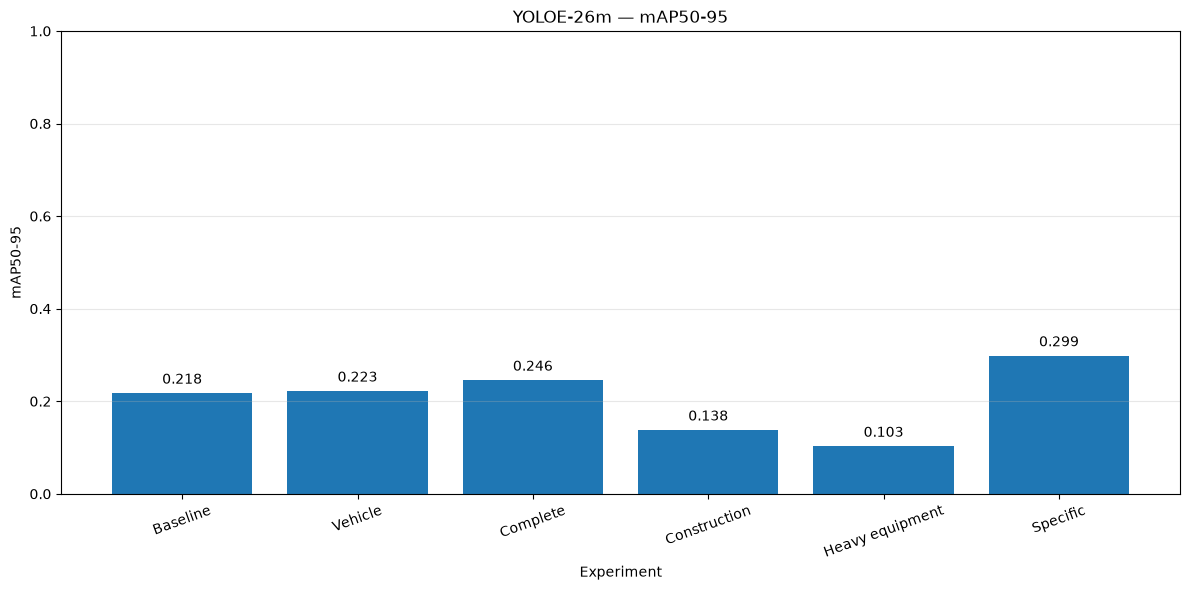

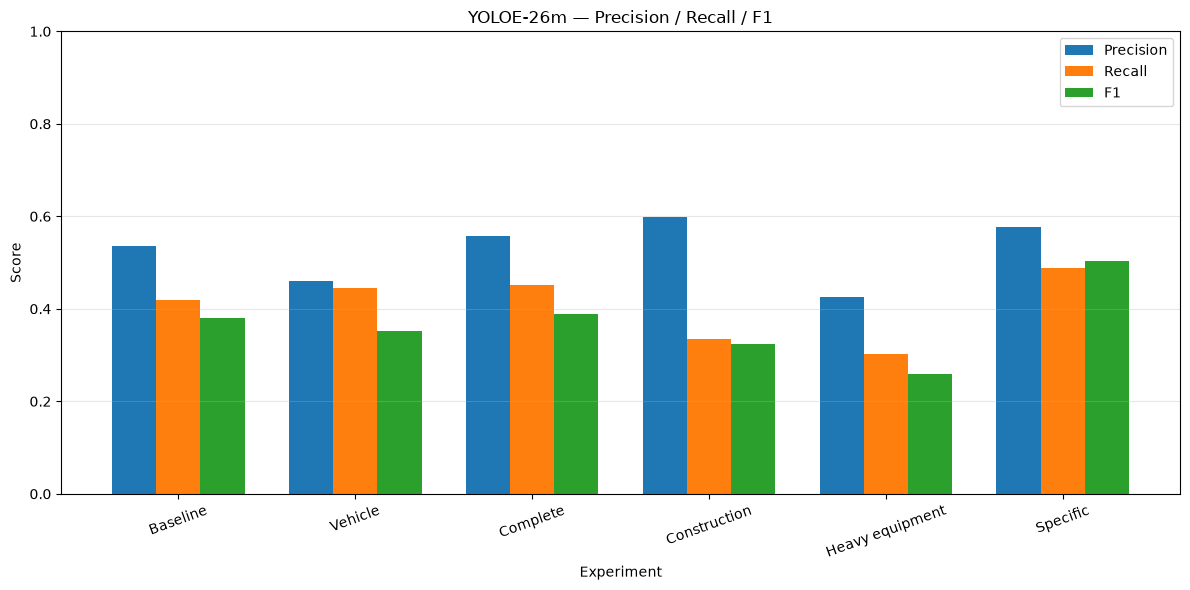

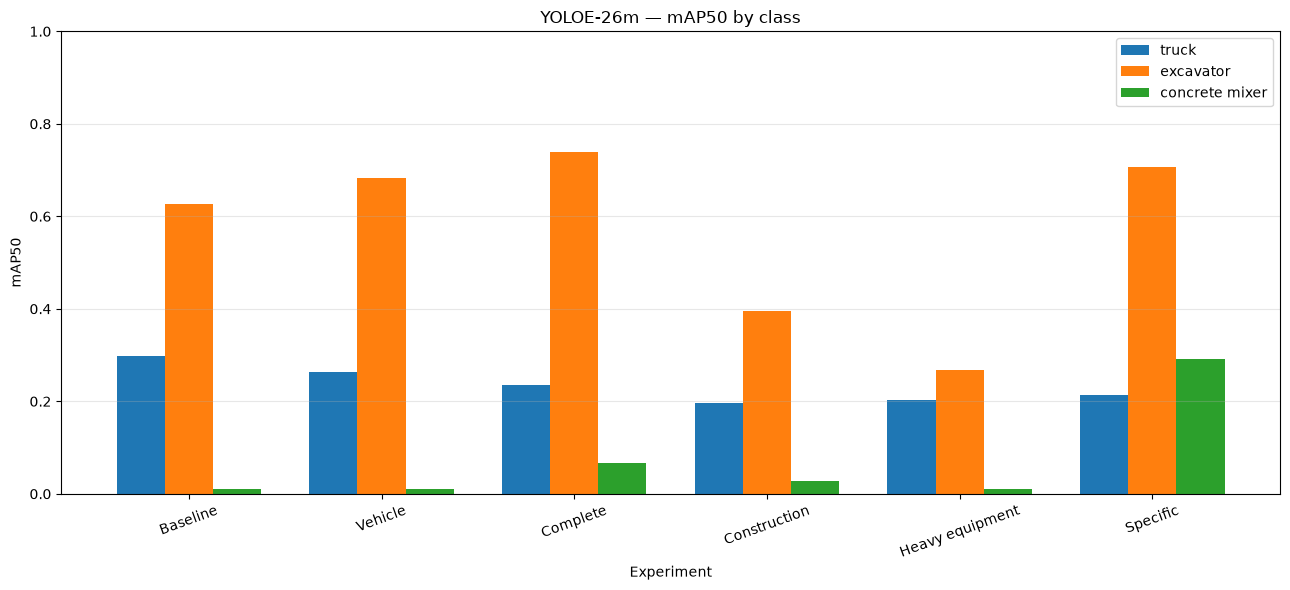

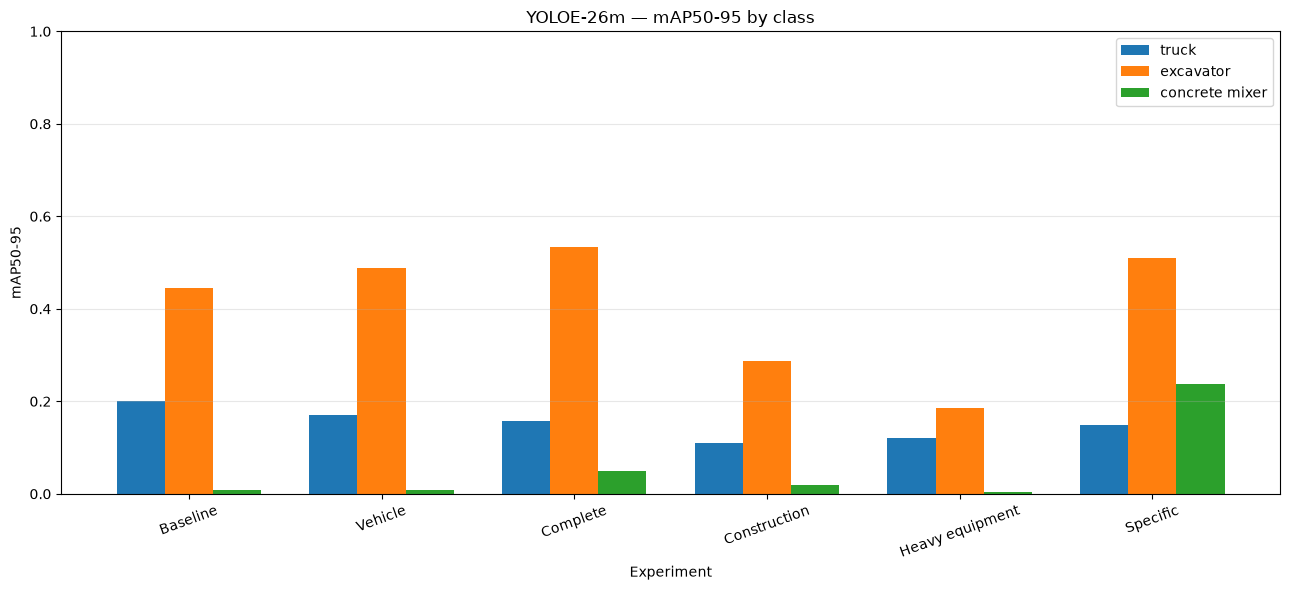

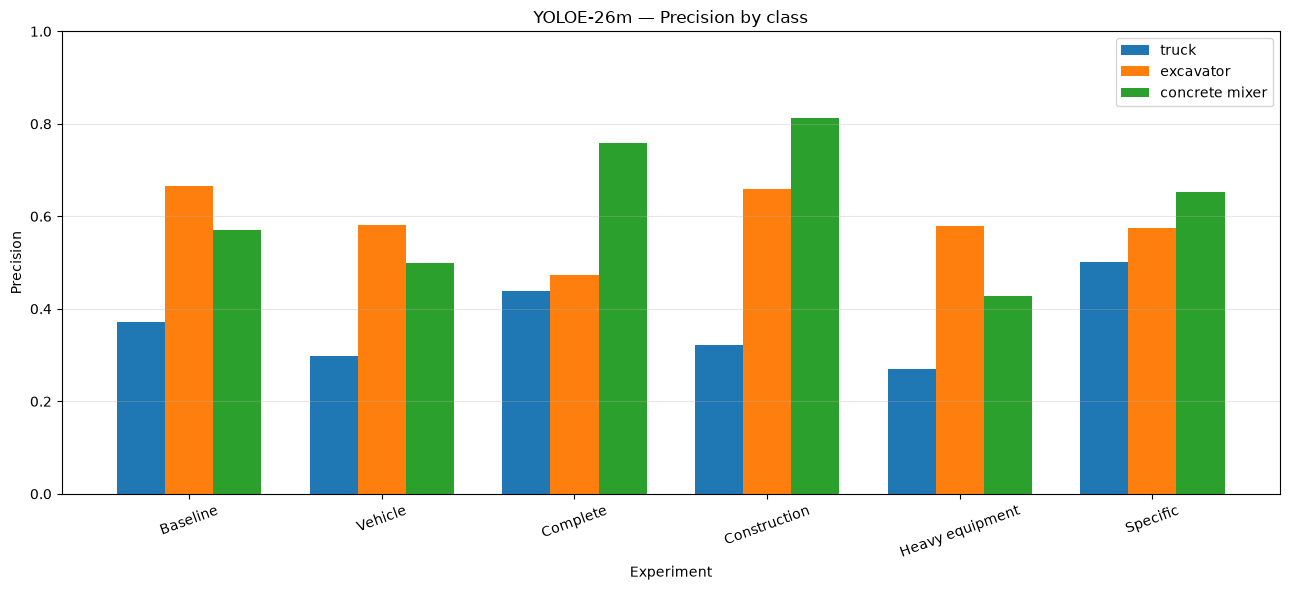

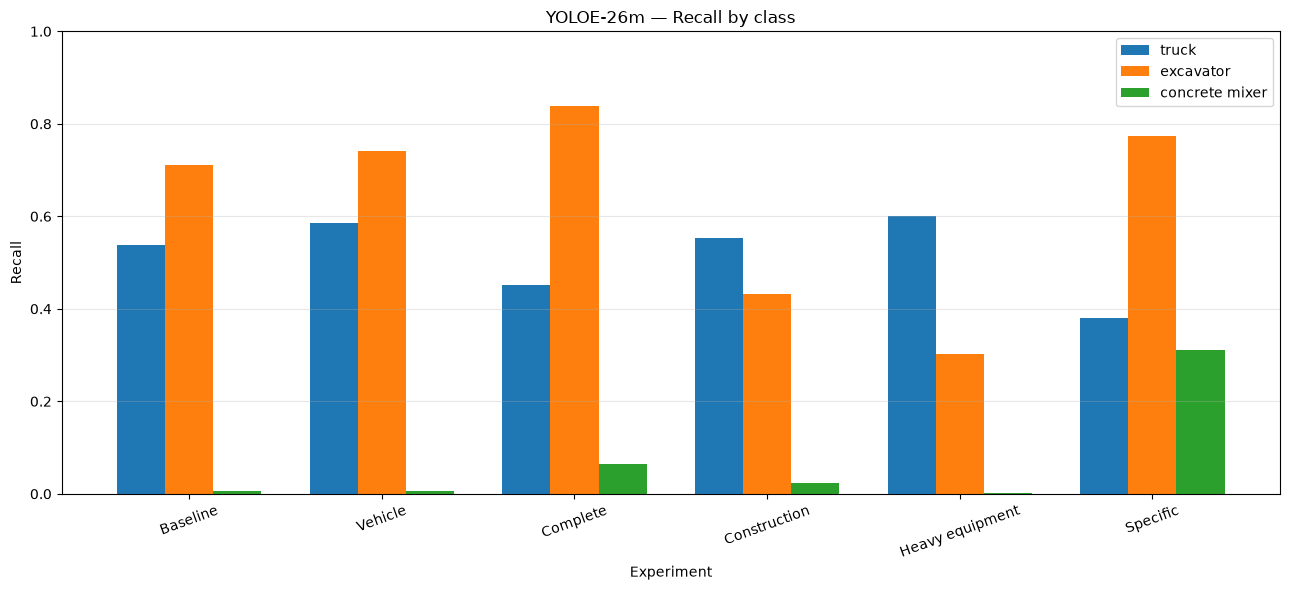

In [9]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = summary.copy()

# Чтобы на графиках эксперименты шли в логическом порядке
experiment_order = list(experiments.keys())

plot_df["experiment"] = pd.Categorical(
    plot_df["experiment"],
    categories=experiment_order,
    ordered=True
)

plot_df = plot_df.sort_values("experiment")

x = np.arange(len(plot_df))
labels = [
    "Baseline",
    "Vehicle",
    "Complete",
    "Construction",
    "Heavy equipment",
    "Specific"
]


# ============================================================
# 1. mAP50
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    x,
    plot_df["mAP50"]
)

plt.xticks(x, labels, rotation=20)
plt.ylabel("mAP50")
plt.xlabel("Experiment")
plt.title("YOLOE-26m — mAP50")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(plot_df["mAP50"]):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ============================================================
# 2. mAP50-95
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    x,
    plot_df["mAP50-95"]
)

plt.xticks(x, labels, rotation=20)
plt.ylabel("mAP50-95")
plt.xlabel("Experiment")
plt.title("YOLOE-26m — mAP50-95")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(plot_df["mAP50-95"]):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ============================================================
# 3. Precision / Recall / F1
# ============================================================

plt.figure(figsize=(12, 6))

width = 0.25

plt.bar(
    x - width,
    plot_df["precision"],
    width,
    label="Precision"
)

plt.bar(
    x,
    plot_df["recall"],
    width,
    label="Recall"
)

plt.bar(
    x + width,
    plot_df["F1"],
    width,
    label="F1"
)

plt.xticks(x, labels, rotation=20)
plt.ylabel("Score")
plt.xlabel("Experiment")
plt.title("YOLOE-26m — Precision / Recall / F1")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 4. mAP50 BY CLASS
# ============================================================

plt.figure(figsize=(13, 6))

width = 0.25

for i, cls in enumerate(eval_classes):

    plt.bar(
        x + (i - 1) * width,
        plot_df[f"{cls}_mAP50"],
        width,
        label=cls
    )

plt.xticks(x, labels, rotation=20)
plt.ylabel("mAP50")
plt.xlabel("Experiment")
plt.title("YOLOE-26m — mAP50 by class")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 5. mAP50-95 BY CLASS
# ============================================================

plt.figure(figsize=(13, 6))

for i, cls in enumerate(eval_classes):

    plt.bar(
        x + (i - 1) * width,
        plot_df[f"{cls}_mAP50-95"],
        width,
        label=cls
    )

plt.xticks(x, labels, rotation=20)
plt.ylabel("mAP50-95")
plt.xlabel("Experiment")
plt.title("YOLOE-26m — mAP50-95 by class")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 6. PRECISION BY CLASS
# ============================================================

plt.figure(figsize=(13, 6))

for i, cls in enumerate(eval_classes):

    plt.bar(
        x + (i - 1) * width,
        plot_df[f"{cls}_P"],
        width,
        label=cls
    )

plt.xticks(x, labels, rotation=20)
plt.ylabel("Precision")
plt.xlabel("Experiment")
plt.title("YOLOE-26m — Precision by class")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 7. RECALL BY CLASS
# ============================================================

plt.figure(figsize=(13, 6))

for i, cls in enumerate(eval_classes):

    plt.bar(
        x + (i - 1) * width,
        plot_df[f"{cls}_R"],
        width,
        label=cls
    )

plt.xticks(x, labels, rotation=20)
plt.ylabel("Recall")
plt.xlabel("Experiment")
plt.title("YOLOE-26m — Recall by class")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()